# **Public Transport Patronage**


## 1. Data Quality Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import duckdb

print("All libraries successfully consolidated and loaded.")

All libraries successfully consolidated and loaded.


In [2]:
# Load dataset
df = pd.read_csv("public_transport.csv")

# Display basic info and first few rows
print("=== Dataset Shape ===")
print(df.shape)
print("\n=== Dataset Info ===")
print(df.info())
print("\n=== First 5 Rows ===")
display(df.head())


=== Dataset Shape ===
(102, 10)

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   _id                 102 non-null    int64 
 1   Year                102 non-null    int64 
 2   Month               102 non-null    int64 
 3   Month name          102 non-null    object
 4   Metropolitan train  102 non-null    int64 
 5   Metropolitan tram   102 non-null    int64 
 6   Metropolitan bus    102 non-null    int64 
 7   V/Line train        102 non-null    int64 
 8   V/Line coach        102 non-null    int64 
 9   Regional bus        102 non-null    object
dtypes: int64(8), object(2)
memory usage: 8.1+ KB
None

=== First 5 Rows ===


,_id,Year,Month,Month name,Metropolitan train,Metropolitan tram,Metropolitan bus,V/Line train,V/Line coach,Regional bus
0,1,2018,1,January,16809932,15231368,7568547,1466256,116568,721229
1,2,2018,2,February,19554477,16980925,10487311,1522981,103197,1118494
2,3,2018,3,March,22659010,19832126,11528895,1809774,117180,1224816
3,4,2018,4,April,20312040,16919872,9592750,1684827,107480,946218
4,5,2018,5,May,22768447,17691427,11263486,1790656,109456,1258704


## Missing and Duplicate Values Assessment

In [3]:
# 1. Missing Value Assessment
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Percentage (%)': missing_percentage})
print("=== Missing Value Assessment ===")
display(missing_df)

# 2. Duplicate Value Assessment
duplicate_count = df.duplicated().sum()
print(f"\n=== Duplicate Value Assessment ===")
print(f"Total duplicate rows: {duplicate_count}")


=== Missing Value Assessment ===


,Missing Count,Percentage (%)
_id,0,0.0
Year,0,0.0
Month,0,0.0
Month name,0,0.0
Metropolitan train,0,0.0
Metropolitan tram,0,0.0
Metropolitan bus,0,0.0
V/Line train,0,0.0
V/Line coach,0,0.0
Regional bus,0,0.0



=== Duplicate Value Assessment ===
Total duplicate rows: 0


## Categorical Consistency and Numeric Distribution / Outlier Detection

=== Categorical Consistency Check ===

Column 'Month name' has 12 unique values:
['January' 'February' 'March' 'April' 'May' 'June' 'July' 'August'
 'September' 'October' 'November' 'December']

Column 'Regional bus' has 102 unique values:
Sample values: ['721229' '1118494' '1224816' '946218' '1258704' '1077970' '967622'
 '1261319' '1033758' '1232418']

=== Numeric Distribution Summary (Millions) ===


,Metropolitan train,Metropolitan tram,Metropolitan bus,V/Line train,V/Line coach
count,102.000000,102.000000,102.000000,102.000000,102.000000
mean,14.339751,11.871074,8.320015,1.554489,0.091335
std,5.467151,4.546364,2.489450,0.597717,0.029095
min,1.887499,1.224017,1.507175,0.222256,0.017602
25%,11.873648,10.086778,7.358225,1.261553,0.074057
50%,14.931630,12.478620,8.837166,1.725826,0.104291
75%,17.814870,14.991294,10.205604,1.960049,0.110993
max,23.045436,19.832126,12.082141,2.952841,0.153998


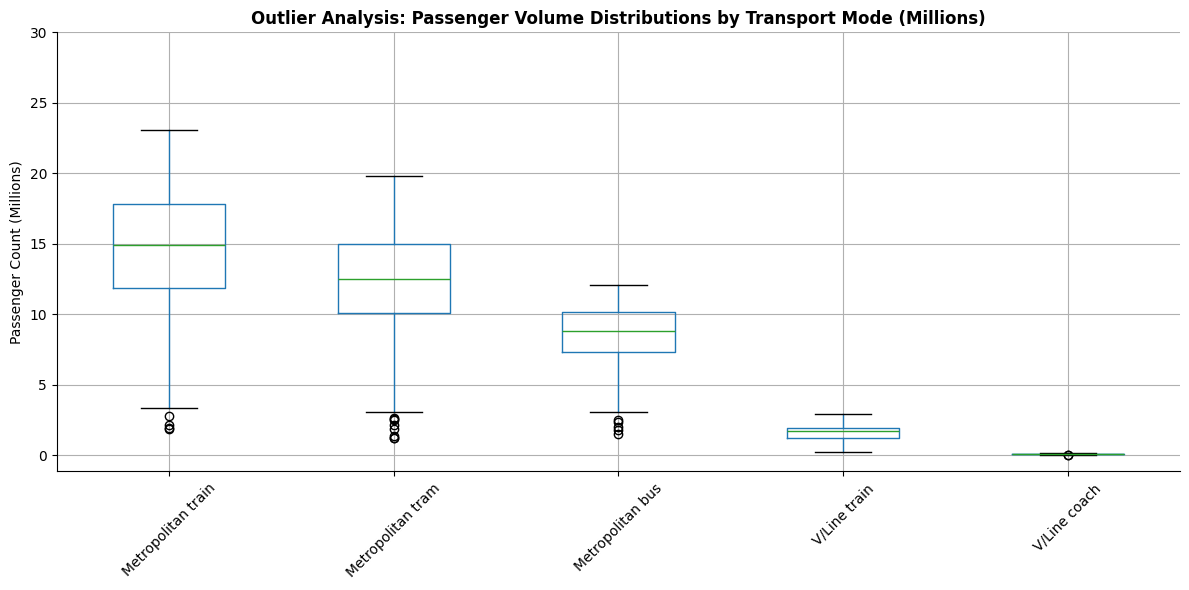

In [4]:
# Identify categorical and numerical columns, excluding non-informative IDs and time units for outlier analysis
categ_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
numer_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Remove ID and Time columns from numerical analysis
exclude_cols = ['_id', 'Year', 'Month']
outlier_cols = [col for col in numer_cols if col not in exclude_cols]

# 3. Categorical Consistency Check
print("=== Categorical Consistency Check ===")
for col in categ_cols:
    unique_vals = df[col].unique()
    print(f"\nColumn '{col}' has {len(unique_vals)} unique values:")
    if len(unique_vals) <= 20:
        print(unique_vals)
    else:
        print(f"Sample values: {unique_vals[:10]}")

# 4. Numeric Distribution and Statistical Summary in Millions (excluding _id, Year, Month)
print("\n=== Numeric Distribution Summary (Millions) ===")
display((df[outlier_cols] / 1e6).describe())

# Boxplot for Outlier Detection in Millions (excluding _id, Year, Month)
if outlier_cols:
    plt.figure(figsize=(12, 6))
    (df[outlier_cols] / 1e6).boxplot()
    plt.title('Outlier Analysis: Passenger Volume Distributions by Transport Mode (Millions)', fontweight='bold')
    plt.ylabel('Passenger Count (Millions)')
    plt.ylim(top=30)
    plt.xticks(rotation=45)

    # Remove top and right spines
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No matching numeric columns available for outlier detection plotting.")

## 2. Data Cleaning

In [5]:
# 1. Reload raw data and clean specifically index 82 ('940930Jan-25')
df = pd.read_csv("public_transport.csv")
df['Regional bus'] = df['Regional bus'].astype(str).str.replace('Jan-25', '', case=False, regex=False)
df['Regional bus'] = pd.to_numeric(df['Regional bus'], errors='coerce').astype(int)

# 2. Save the cleaned dataset to /content/public_transport_clean.csv
cleaned_file_path = "/content/public_transport_clean.csv"
df.to_csv(cleaned_file_path, index=False)
print(f"Saved cleaned dataset to: {cleaned_file_path}")

# 3. Connect to DuckDB and create the clean table
con = duckdb.connect(database=':memory:')
con.execute("CREATE OR REPLACE TABLE patronage AS SELECT * FROM df")

# Verify
print("=== Cleaned Regional bus Column Type ===")
print(df['Regional bus'].dtype)
display(df.loc[[82], ['Year', 'Month', 'Month name', 'Regional bus']])

Saved cleaned dataset to: /content/public_transport_clean.csv
=== Cleaned Regional bus Column Type ===
int64


,Year,Month,Month name,Regional bus
82,2024,11,November,940930


## 3. Creating table in DUCKDB and using SQL to answer busienss questions

In [6]:
# Connect to an in-memory DuckDB database
con = duckdb.connect(database=':memory:')

# Create a table from the existing Pandas DataFrame 'df'
con.execute("CREATE TABLE patronage AS SELECT * FROM df")

# Verify the table creation and inspect its structure
print("=== DuckDB Tables ===")
display(con.execute("SHOW TABLES").df())

print("\n=== First 5 Rows from DuckDB patronage Table ===")
display(con.execute("SELECT * FROM patronage LIMIT 5").df())

=== DuckDB Tables ===


,name
0,patronage



=== First 5 Rows from DuckDB patronage Table ===


,_id,Year,Month,Month name,Metropolitan train,Metropolitan tram,Metropolitan bus,V/Line train,V/Line coach,Regional bus
0,1,2018,1,January,16809932,15231368,7568547,1466256,116568,721229
1,2,2018,2,February,19554477,16980925,10487311,1522981,103197,1118494
2,3,2018,3,March,22659010,19832126,11528895,1809774,117180,1224816
3,4,2018,4,April,20312040,16919872,9592750,1684827,107480,946218
4,5,2018,5,May,22768447,17691427,11263486,1790656,109456,1258704


### Q1. Trend Analysis of Public Transport Patronage Over Time
To trace how public transport has changed over time, we will run a SQL query calculating total patronage per month by combining all public transit categories. Note that we cast `Regional bus` to an `INTEGER` to ensure correct addition.

In [7]:
# SQL query to aggregate monthly patronage using our clean integer columns (no TRY_CAST needed anymore)
query = """
SELECT
    Year,
    Month,
    "Month name" AS Month_Name,
    ("Metropolitan train" +
     "Metropolitan tram" +
     "Metropolitan bus" +
     "V/Line train" +
     "V/Line coach" +
     "Regional bus") AS Total_Patronage
FROM patronage
ORDER BY Year, Month;
"""

time_trends_df = con.execute(query).df()
display(time_trends_df.head())

,Year,Month,Month_Name,Total_Patronage
0,2018,1,January,41913900
1,2018,2,February,49767385
2,2018,3,March,57171801
3,2018,4,April,49563187
4,2018,5,May,54882176


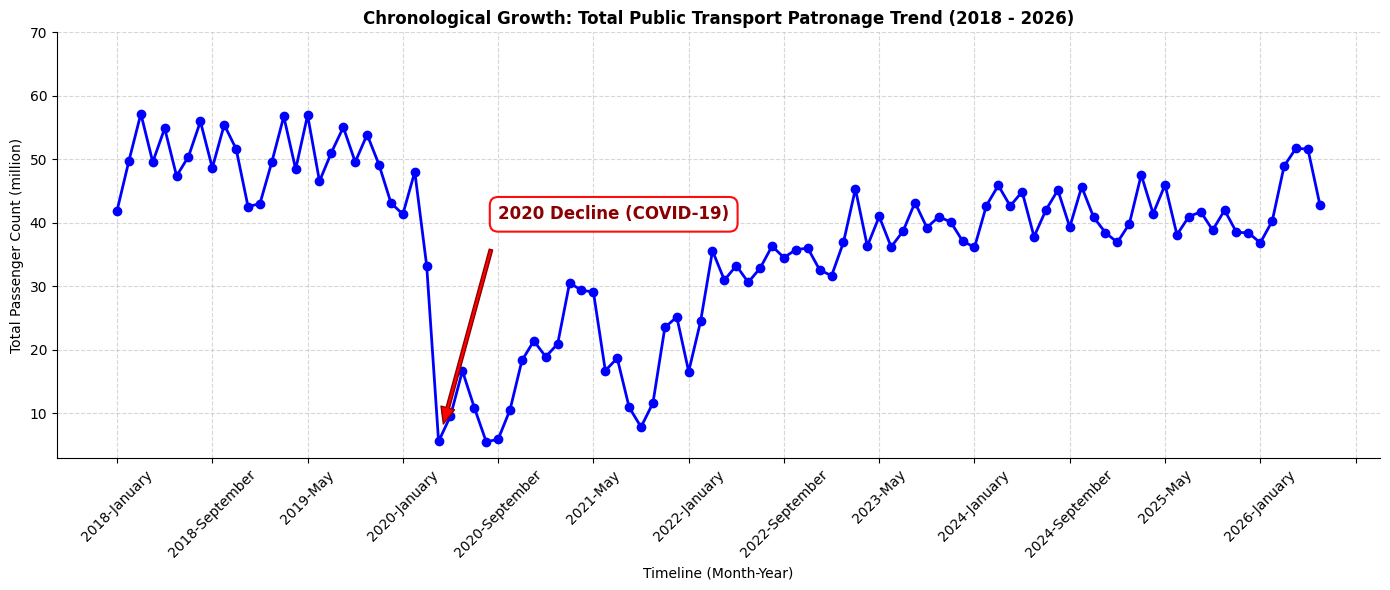

In [26]:
# Visualize the trend over time with y-axis in millions
plt.figure(figsize=(14, 6))

x_values = time_trends_df['Year'].astype(str) + '-' + time_trends_df['Month_Name']
y_values = time_trends_df['Total_Patronage'] / 1e6

plt.plot(
    x_values,
    y_values,
    marker='o',
    color='b',
    linewidth=2
)
plt.title('Chronological Growth: Total Public Transport Patronage Trend (2018 - 2026)', fontweight='bold')
plt.xlabel('Timeline (Month-Year)')
plt.ylabel('Total Passenger Count (million)')
plt.ylim(top=70)

# Reduce x-axis ticks clutter
ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=15))
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

# Annotate the decline in 2020 (April 2020 hit a record low)
# Let's find the exact index of April 2020 to position our annotation accurately
try:
    idx_2020_april = time_trends_df[(time_trends_df['Year'] == 2020) & (time_trends_df['Month_Name'] == 'April')].index[0]
    x_anno = x_values.iloc[idx_2020_april]
    y_anno = y_values.iloc[idx_2020_april]

    # Moved the annotation box higher (y_anno + 32) and horizontally offset to avoid overlapping the line segment
    ax.annotate(
        '2020 Decline (COVID-19)',
        xy=(idx_2020_april, y_anno),
        xytext=(idx_2020_april + 5, y_anno + 35),
        arrowprops=dict(
            facecolor='red',
            edgecolor='darkred',
            shrink=0.08,
            width=2.5,
            headwidth=10
        ),
        fontweight='bold',
        fontsize=12,
        color='darkred',
        bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='red', lw=1.5, alpha=0.95)
    )
except IndexError:
    pass

# Despine the top and right borders
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

### Q2. Share of Patronage by Transport Mode
To determine which transport modes carry the most passengers, we will calculate the cumulative sum of each mode's patronage across the entire dataset, cast the `Regional bus` string column to integer, and calculate the overall percentage share for each mode.

In [9]:
# SQL query to aggregate overall volume and calculate shares by transport mode
share_query = """
SELECT
    SUM("Metropolitan train") AS "Metropolitan Train",
    SUM("Metropolitan tram") AS "Metropolitan Tram",
    SUM("Metropolitan bus") AS "Metropolitan Bus",
    SUM("V/Line train") AS "V/Line Train",
    SUM("V/Line coach") AS "V/Line Coach",
    SUM("Regional bus") AS "Regional Bus"
FROM patronage;
"""

# Execute query and reshape the result for plotting
share_df = con.execute(share_query).df().T.reset_index()
share_df.columns = ['Transport Mode', 'Total Patronage']
share_df = share_df.sort_values(by='Total Patronage', ascending=False)

# Calculate percentage shares
total_sum = share_df['Total Patronage'].sum()
share_df['Share (%)'] = (share_df['Total Patronage'] / total_sum) * 100

display(share_df)

,Transport Mode,Total Patronage,Share (%)
0,Metropolitan Train,1.462655e+09,38.609727
1,Metropolitan Tram,1.210850e+09,31.962823
2,Metropolitan Bus,8.486415e+08,22.401610
3,V/Line Train,1.585578e+08,4.185455
5,Regional Bus,9.828631e+07,2.594466
4,V/Line Coach,9.316200e+06,0.245920


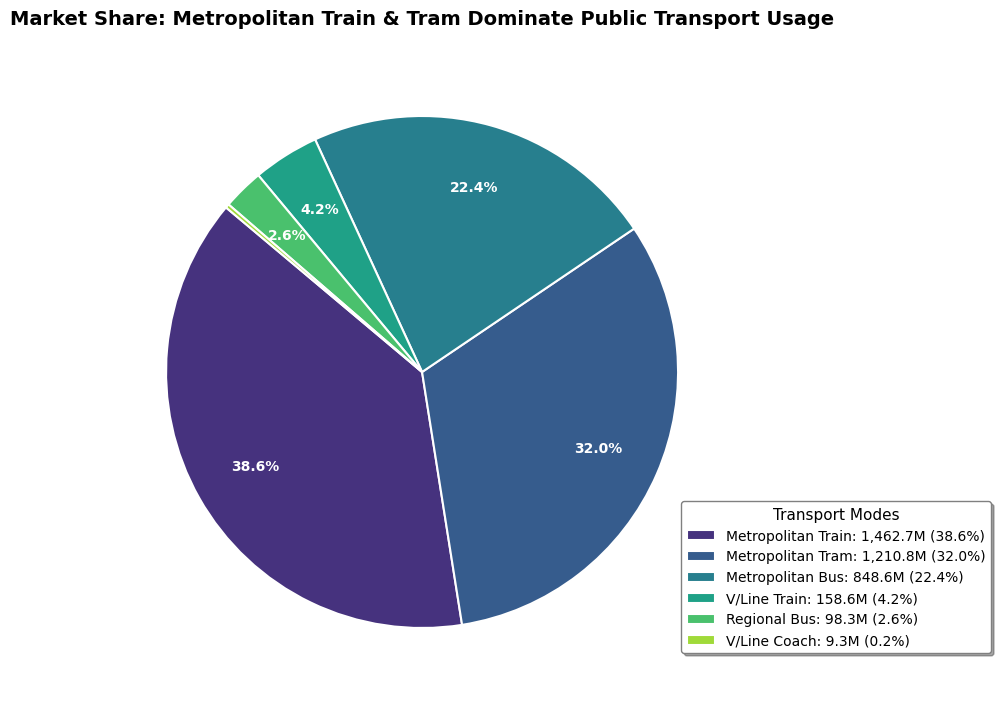

In [30]:
# Visualize transport mode shares
plt.figure(figsize=(12, 8))

# Create the pie chart without labels to avoid overlapping text
wedges, texts, autotexts = plt.pie(
    share_df['Total Patronage'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('viridis', len(share_df)),
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    pctdistance=0.75
)

# Style percentages on slices for visibility - hide very small ones to avoid overlapping
for autotext in autotexts:
    pct_val = float(autotext.get_text().strip('%'))
    if pct_val < 1.0:
        autotext.set_visible(False)  # Hide <1% slice text because it is already clearly detailed in the legend
    else:
        autotext.set_size(10)
        autotext.set_weight('bold')
        autotext.set_color('white')

# Generate customized legend labels showing mode, value in millions, and percent share
legend_labels = []
for idx, row in share_df.iterrows():
    mode = row['Transport Mode']
    val_m = row['Total Patronage'] / 1e6
    pct = row['Share (%)']
    legend_labels.append(f"{mode}: {val_m:,.1f}M ({pct:.1f}%)")

# Add the legend to the bottom right of the chart frame safely with adjusted bbox
plt.legend(
    wedges,
    legend_labels,
    title="Transport Modes",
    title_fontsize='11',
    loc="lower right",
    bbox_to_anchor=(1.40, 0.05),
    frameon=True,
    shadow=True,
    edgecolor='gray'
)

plt.title('Market Share: Metropolitan Train & Tram Dominate Public Transport Usage', fontweight='bold', fontsize=14, pad=20)

# Adjust layout margins explicitly to guarantee the legend does not get clipped on the right
plt.subplots_adjust(right=0.72, left=0.05, top=0.90, bottom=0.10)
plt.show()

### Q3. Month-on-Month (MoM) and Year-on-Year (YoY) Patronage Changes
We will use a SQL query utilizing window functions (`LAG`) to obtain:
- **Month-on-Month (MoM) Change**: Compares the current month's total patronage to the immediately preceding chronological month.
- **Year-on-Year (YoY) Change**: Compares the current month's total patronage to the same month of the previous calendar year.

In [11]:
# SQL query to compute MoM and YoY patronage dynamics
change_query = """
WITH monthly_totals AS (
    SELECT
        Year,
        Month,
        "Month name" AS Month_Name,
        ("Metropolitan train" +
         "Metropolitan tram" +
         "Metropolitan bus" +
         "V/Line train" +
         "V/Line coach" +
         "Regional bus") AS Total_Patronage
    FROM patronage
),
lagged_totals AS (
    SELECT
        Year,
        Month,
        Month_Name,
        Total_Patronage,
        LAG(Total_Patronage, 1) OVER (ORDER BY Year, Month) AS Prev_Month_Patronage,
        LAG(Total_Patronage, 12) OVER (ORDER BY Year, Month) AS Prev_Year_Patronage
    FROM monthly_totals
)
SELECT
    Year,
    Month_Name,
    Total_Patronage,

    -- Month-on-Month Changes
    (Total_Patronage - Prev_Month_Patronage) AS MoM_Raw_Change,
    ROUND(((Total_Patronage - Prev_Month_Patronage) / Prev_Month_Patronage) * 100, 2) AS "MoM_Change_%",

    -- Year-on-Year Changes
    (Total_Patronage - Prev_Year_Patronage) AS YoY_Raw_Change,
    ROUND(((Total_Patronage - Prev_Year_Patronage) / Prev_Year_Patronage) * 100, 2) AS "YoY_Change_%"
FROM lagged_totals
ORDER BY Year, Month;
"""

# Execute query and display results
change_df = con.execute(change_query).df()
display(change_df.head(15))

,Year,Month_Name,Total_Patronage,MoM_Raw_Change,MoM_Change_%,YoY_Raw_Change,YoY_Change_%
0,2018,January,41913900,<NA>,NaN,<NA>,NaN
1,2018,February,49767385,7853485,18.74,<NA>,NaN
2,2018,March,57171801,7404416,14.88,<NA>,NaN
3,2018,April,49563187,-7608614,-13.31,<NA>,NaN
4,2018,May,54882176,5318989,10.73,<NA>,NaN
5,2018,June,47362542,-7519634,-13.70,<NA>,NaN
6,2018,July,50434635,3072093,6.49,<NA>,NaN
7,2018,August,55956404,5521769,10.95,<NA>,NaN
8,2018,September,48642630,-7313774,-13.07,<NA>,NaN
9,2018,October,55437325,6794695,13.97,<NA>,NaN


### Q4. Recovery and Growth Analysis by Transport Mode
To determine which transport modes have experienced the strongest recovery or growth, we compare the average monthly patronage from the baseline year (**2018**) against the most recent complete year of data (**2025**).

In [12]:
# SQL query to compare 2018 baseline vs 2025 recovery by mode
recovery_query = """
WITH yearly_averages AS (
    SELECT
        Year,
        AVG("Metropolitan train") AS Avg_Train,
        AVG("Metropolitan tram") AS Avg_Tram,
        AVG("Metropolitan bus") AS Avg_Bus,
        AVG("V/Line train") AS Avg_VLine_Train,
        AVG("V/Line coach") AS Avg_VLine_Coach,
        AVG("Regional bus") AS Avg_Regional_Bus
    FROM patronage
    WHERE Year IN (2018, 2025)
    GROUP BY Year
),
pivoted AS (
    SELECT
        'Metropolitan Train' AS Mode,
        MAX(CASE WHEN Year = 2018 THEN Avg_Train END) AS Baseline_2018,
        MAX(CASE WHEN Year = 2025 THEN Avg_Train END) AS Current_2025
    FROM yearly_averages
    UNION ALL
    SELECT
        'Metropolitan Tram',
        MAX(CASE WHEN Year = 2018 THEN Avg_Tram END),
        MAX(CASE WHEN Year = 2025 THEN Avg_Tram END)
    FROM yearly_averages
    UNION ALL
    SELECT
        'Metropolitan Bus',
        MAX(CASE WHEN Year = 2018 THEN Avg_Bus END),
        MAX(CASE WHEN Year = 2025 THEN Avg_Bus END)
    FROM yearly_averages
    UNION ALL
    SELECT
        'V/Line Train',
        MAX(CASE WHEN Year = 2018 THEN Avg_VLine_Train END),
        MAX(CASE WHEN Year = 2025 THEN Avg_VLine_Train END)
    FROM yearly_averages
    UNION ALL
    SELECT
        'V/Line Coach',
        MAX(CASE WHEN Year = 2018 THEN Avg_VLine_Coach END),
        MAX(CASE WHEN Year = 2025 THEN Avg_VLine_Coach END)
    FROM yearly_averages
    UNION ALL
    SELECT
        'Regional Bus',
        MAX(CASE WHEN Year = 2018 THEN Avg_Regional_Bus END),
        MAX(CASE WHEN Year = 2025 THEN Avg_Regional_Bus END)
    FROM yearly_averages
)
SELECT
    Mode,
    ROUND(Baseline_2018, 0) AS Monthly_Avg_2018,
    ROUND(Current_2025, 0) AS Monthly_Avg_2025,
    ROUND(Current_2025 - Baseline_2018, 0) AS Absolute_Change,
    ROUND(((Current_2025 - Baseline_2018) / Baseline_2018) * 100, 2) AS "Recovery_or_Growth_%"
FROM pivoted
ORDER BY "Recovery_or_Growth_%" DESC;
"""

# Execute query and display results
recovery_df = con.execute(recovery_query).df()
display(recovery_df)

,Mode,Monthly_Avg_2018,Monthly_Avg_2025,Absolute_Change,Recovery_or_Growth_%
0,V/Line Train,1691153.0,2143421.0,452267.0,26.74
1,V/Line Coach,110422.0,113240.0,2818.0,2.55
2,Metropolitan Bus,10066963.0,9368558.0,-698405.0,-6.94
3,Regional Bus,1075363.0,985398.0,-89965.0,-8.37
4,Metropolitan Train,20376272.0,15434072.0,-4942200.0,-24.25
5,Metropolitan Tram,17120841.0,12805964.0,-4314877.0,-25.20


### Q5. Seasonal Patterns in Passenger Demand
To determine if there are recurring seasonal patterns, we will calculate the average monthly patronage across all recorded years (2018–2026).

In [13]:
# SQL query to aggregate monthly average patronage across all years
seasonal_query = """
WITH monthly_totals AS (
    SELECT
        Year,
        Month,
        "Month name" AS Month_Name,
        ("Metropolitan train" +
         "Metropolitan tram" +
         "Metropolitan bus" +
         "V/Line train" +
         "V/Line coach" +
         "Regional bus") AS Total_Patronage
    FROM patronage
)
SELECT
    Month,
    Month_Name,
    ROUND(AVG(Total_Patronage), 0) AS Avg_Monthly_Patronage
FROM monthly_totals
GROUP BY Month, Month_Name
ORDER BY Month;
"""

seasonal_df = con.execute(seasonal_query).df()
display(seasonal_df)

,Month,Month_Name,Avg_Monthly_Patronage
0,1,January,33688786.0
1,2,February,39164375.0
2,3,March,44546641.0
3,4,April,37332873.0
4,5,May,40796425.0
5,6,June,34759676.0
6,7,July,35691979.0
7,8,August,36722663.0
8,9,September,32975433.0
9,10,October,36976996.0


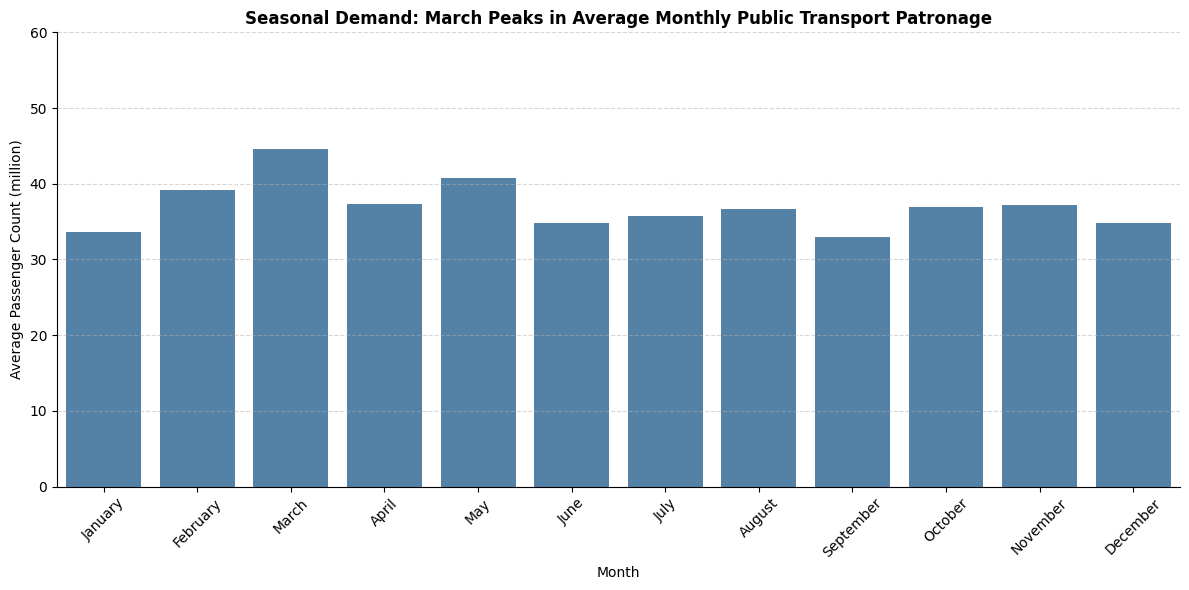

In [14]:
# Visualize monthly seasonality with a single cohesive color (scaled to millions)
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Month_Name',
    y=seasonal_df['Avg_Monthly_Patronage'] / 1e6,
    data=seasonal_df,
    color='steelblue'
)
plt.title('Seasonal Demand: March Peaks in Average Monthly Public Transport Patronage', fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average Passenger Count (million)')
plt.ylim(top=60)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Despine the top and right borders
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

### Q6. Demand Fluctuations by Transport Mode
To pinpoint which transport modes experience the most volatile demand patterns, we run a SQL query calculating statistical dispersion metrics (Standard Deviation, Range, and Coefficient of Variation) across all recorded months. Evaluating both absolute volatility (Standard Deviation) and relative volatility (Coefficient of Variation) ensures a fair comparison between high-volume and low-volume transit modes.

In [15]:
# SQL query to calculate demand dispersion metrics for each mode
fluctuation_query = """
WITH monthly_stats AS (
    SELECT
        'Metropolitan Train' AS Mode,
        STDDEV("Metropolitan train") AS Std_Dev,
        AVG("Metropolitan train") AS Mean_Value,
        MAX("Metropolitan train") - MIN("Metropolitan train") AS Range_Value
    FROM patronage
    UNION ALL
    SELECT
        'Metropolitan Tram',
        STDDEV("Metropolitan tram"),
        AVG("Metropolitan tram"),
        MAX("Metropolitan tram") - MIN("Metropolitan tram")
    FROM patronage
    UNION ALL
    SELECT
        'Metropolitan Bus',
        STDDEV("Metropolitan bus"),
        AVG("Metropolitan bus"),
        MAX("Metropolitan bus") - MIN("Metropolitan bus")
    FROM patronage
    UNION ALL
    SELECT
        'V/Line Train',
        STDDEV("V/Line train"),
        AVG("V/Line train"),
        MAX("V/Line train") - MIN("V/Line train")
    FROM patronage
    UNION ALL
    SELECT
        'V/Line Coach',
        STDDEV("V/Line coach"),
        AVG("V/Line coach"),
        MAX("V/Line coach") - MIN("V/Line coach")
    FROM patronage
    UNION ALL
    SELECT
        'Regional Bus',
        STDDEV("Regional bus"),
        AVG("Regional bus"),
        MAX("Regional bus") - MIN("Regional bus")
    FROM patronage
)
SELECT
    Mode,
    ROUND(Mean_Value, 0) AS Monthly_Mean,
    ROUND(Std_Dev, 0) AS Std_Deviation,
    ROUND(Range_Value, 0) AS Demand_Range,
    ROUND((Std_Dev / Mean_Value) * 100, 2) AS "Coefficient_of_Variation_%"
FROM monthly_stats
ORDER BY "Coefficient_of_Variation_%" DESC;
"""

fluctuation_df = con.execute(fluctuation_query).df()
display(fluctuation_df)

,Mode,Monthly_Mean,Std_Deviation,Demand_Range,Coefficient_of_Variation_%
0,V/Line Train,1554489.0,597717.0,2730585,38.45
1,Metropolitan Tram,11871074.0,4546364.0,18608109,38.30
2,Metropolitan Train,14339751.0,5467151.0,21157937,38.13
3,V/Line Coach,91335.0,29095.0,136396,31.86
4,Metropolitan Bus,8320015.0,2489450.0,10574966,29.92
5,Regional Bus,963591.0,229088.0,1059838,23.77


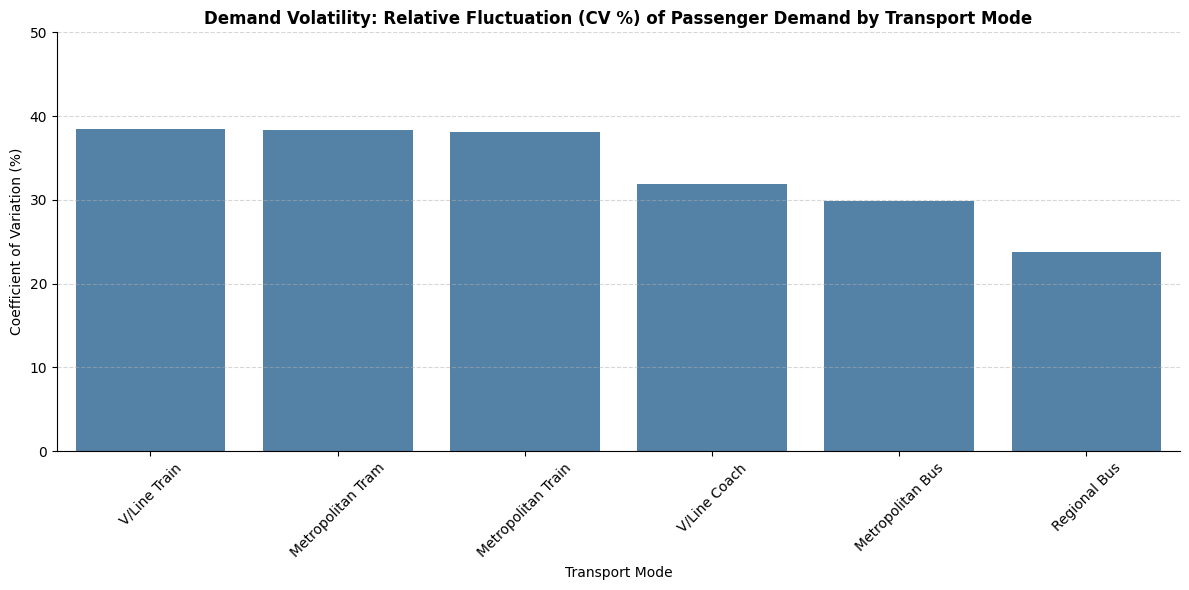

In [16]:
# Visualize relative fluctuations (Coefficient of Variation) across transport modes
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Mode',
    y='Coefficient_of_Variation_%',
    data=fluctuation_df,
    color='steelblue'
)
plt.title('Demand Volatility: Relative Fluctuation (CV %) of Passenger Demand by Transport Mode', fontweight='bold')
plt.xlabel('Transport Mode')
plt.ylabel('Coefficient of Variation (%)')
plt.ylim(top=50)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Q7. Months with Unusually Large MoM Changes in Patronage
To identify months with "unusually large" changes, we calculate the Month-on-Month (MoM) percentage change for each chronological month, compute the average and standard deviation of these changes across the entire dataset, and extract the months where the change deviates by more than 1.5 standard deviations from the historical mean.

In [17]:
# SQL query to identify statistical outliers in month-on-month patronage changes
outlier_query = """
WITH monthly_totals AS (
    SELECT
        Year,
        Month,
        "Month name" AS Month_Name,
        ("Metropolitan train" +
         "Metropolitan tram" +
         "Metropolitan bus" +
         "V/Line train" +
         "V/Line coach" +
         "Regional bus") AS Total_Patronage
    FROM patronage
),
calculated_changes AS (
    SELECT
        Year,
        Month,
        Month_Name,
        Total_Patronage,
        LAG(Total_Patronage, 1) OVER (ORDER BY Year, Month) AS Prev_Patronage,
        ROUND(((Total_Patronage - LAG(Total_Patronage, 1) OVER (ORDER BY Year, Month)) / LAG(Total_Patronage, 1) OVER (ORDER BY Year, Month)) * 100, 2) AS MoM_Change_Percent
    FROM monthly_totals
),
stats AS (
    SELECT
        AVG(MoM_Change_Percent) AS avg_change,
        STDDEV(MoM_Change_Percent) AS stddev_change
    FROM calculated_changes
    WHERE MoM_Change_Percent IS NOT NULL
)
SELECT
    Year,
    Month_Name,
    ROUND(Total_Patronage / 1e6, 2) AS "Total_Patronage_Millions",
    MoM_Change_Percent AS "MoM_Change_%",
    ROUND((MoM_Change_Percent - avg_change) / stddev_change, 2) AS Z_Score
FROM calculated_changes, stats
WHERE ABS(MoM_Change_Percent - avg_change) > 1.5 * stddev_change
ORDER BY ABS(MoM_Change_Percent) DESC;
"""

outlier_changes_df = con.execute(outlier_query).df()
display(outlier_changes_df)

,Year,Month_Name,Total_Patronage_Millions,MoM_Change_%,Z_Score
0,2021,November,23.50,102.57,3.78
1,2020,April,5.54,-83.33,-3.32
2,2020,October,10.54,79.34,2.89
3,2020,June,16.66,74.13,2.69
4,2020,November,18.30,73.64,2.68
5,2020,May,9.57,72.73,2.64
6,2020,August,5.49,-49.53,-2.03
7,2021,October,11.60,48.40,1.71
8,2022,February,24.46,47.75,1.69
9,2021,March,30.52,45.77,1.61


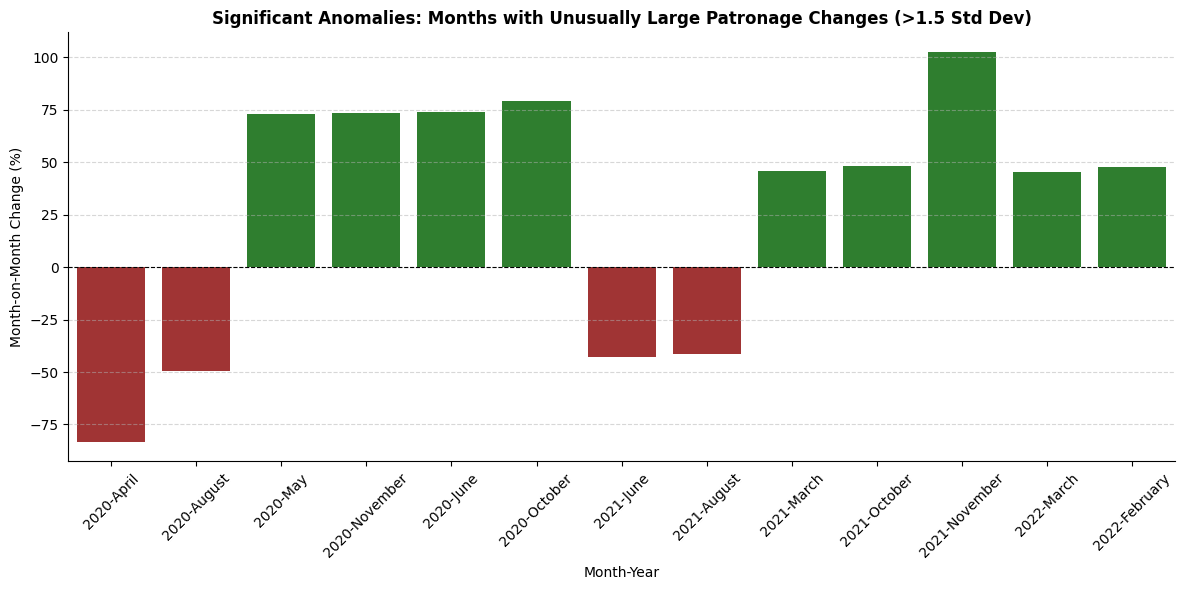

In [18]:
# Plot the unusually large changes chronologically
outliers_plot_df = outlier_changes_df.sort_values(by=['Year', 'MoM_Change_%'])
plt.figure(figsize=(12, 6))
colors = ['firebrick' if x < 0 else 'forestgreen' for x in outliers_plot_df['MoM_Change_%']]

sns.barplot(
    x=outliers_plot_df['Year'].astype(str) + '-' + outliers_plot_df['Month_Name'],
    y=outliers_plot_df['MoM_Change_%'],
    palette=colors,
    hue=outliers_plot_df['Year'].astype(str) + '-' + outliers_plot_df['Month_Name'],
    legend=False
)

plt.title('Significant Anomalies: Months with Unusually Large Patronage Changes (>1.5 Std Dev)', fontweight='bold')
plt.xlabel('Month-Year')
plt.ylabel('Month-on-Month Change (%)')
plt.xticks(rotation=45)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(axis='y', linestyle='--', alpha=0.5)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Q8. Recent Patronage Trends for Management Monitoring
To provide management with a clear view of current performance, we run a SQL query focusing on the last 12 chronological months in our dataset. For each month, we calculate total passenger demand, Month-on-Month (MoM) growth, and Year-on-Year (YoY) performance compared to the same month of the previous year.

In [19]:
# SQL query to extract the most recent 12 months of trends
recent_trends_query = """
WITH monthly_totals AS (
    SELECT
        Year,
        Month,
        "Month name" AS Month_Name,
        ("Metropolitan train" +
         "Metropolitan tram" +
         "Metropolitan bus" +
         "V/Line train" +
         "V/Line coach" +
         "Regional bus") AS Total_Patronage
    FROM patronage
),
lagged_totals AS (
    SELECT
        Year,
        Month,
        Month_Name,
        Total_Patronage,
        LAG(Total_Patronage, 1) OVER (ORDER BY Year, Month) AS Prev_Month,
        LAG(Total_Patronage, 12) OVER (ORDER BY Year, Month) AS Prev_Year
    FROM monthly_totals
)
SELECT
    Year,
    Month_Name,
    ROUND(Total_Patronage / 1e6, 2) AS Total_Patronage_Millions,
    ROUND(((Total_Patronage - Prev_Month) / Prev_Month) * 100, 2) AS "MoM_Change_%",
    ROUND(((Total_Patronage - Prev_Year) / Prev_Year) * 100, 2) AS "YoY_Change_%"
FROM lagged_totals
ORDER BY Year DESC, Month DESC
LIMIT 12;
"""

recent_trends_df = con.execute(recent_trends_query).df()
# Reverse to show chronological order
recent_trends_df = recent_trends_df.iloc[::-1].reset_index(drop=True)
display(recent_trends_df)

,Year,Month_Name,Total_Patronage_Millions,MoM_Change_%,YoY_Change_%
0,2025,July,40.97,7.49,-2.49
1,2025,August,41.72,1.84,-7.58
2,2025,September,38.84,-6.90,-1.20
3,2025,October,41.98,8.08,-8.07
4,2025,November,38.48,-8.33,-5.90
5,2025,December,38.42,-0.16,0.02
6,2026,January,36.83,-4.14,-0.23
7,2026,February,40.27,9.35,1.16
8,2026,March,48.93,21.51,2.90
9,2026,April,51.75,5.76,24.90


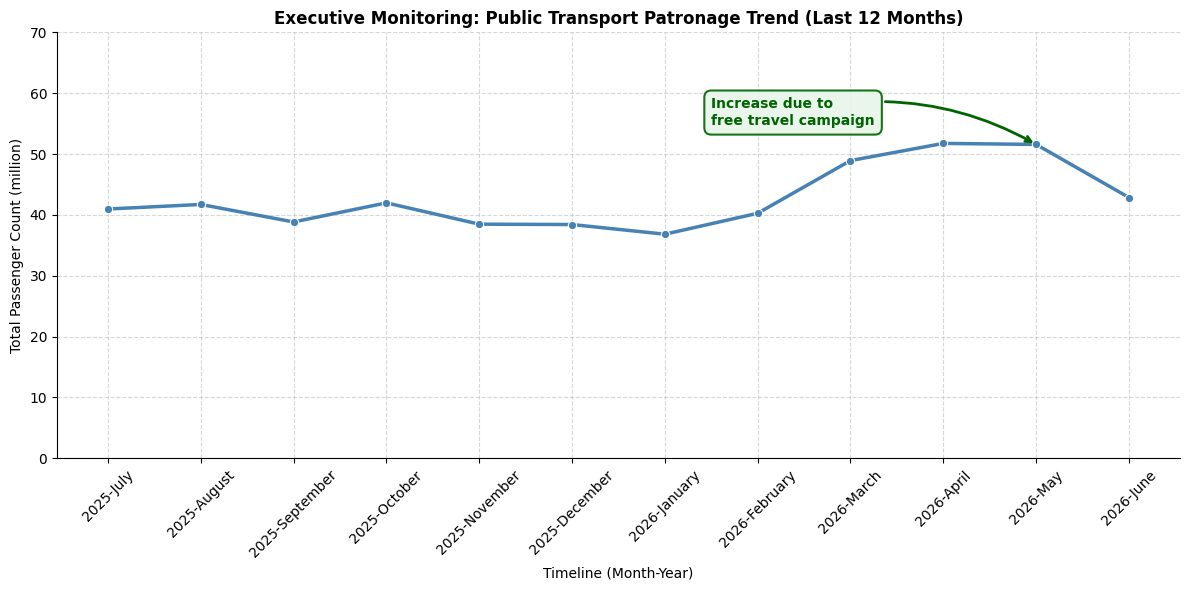

In [33]:
# Visualize the most recent 12-month trend
plt.figure(figsize=(12, 6))
x_dates = recent_trends_df['Year'].astype(str) + '-' + recent_trends_df['Month_Name']
y_values = recent_trends_df['Total_Patronage_Millions']

sns.lineplot(
    x=x_dates,
    y=y_values,
    marker='o',
    color='steelblue',
    linewidth=2.5
)
plt.title('Executive Monitoring: Public Transport Patronage Trend (Last 12 Months)', fontweight='bold')
plt.xlabel('Timeline (Month-Year)')
plt.ylabel('Total Passenger Count (million)')
plt.ylim(bottom=0, top=70)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

# Annotate the increase from 2026-January to 2026-May due to free travel
try:
    idx_jan = recent_trends_df[(recent_trends_df['Year'] == 2026) & (recent_trends_df['Month_Name'] == 'January')].index[0]
    idx_may = recent_trends_df[(recent_trends_df['Year'] == 2026) & (recent_trends_df['Month_Name'] == 'May')].index[0]

    x_jan, y_jan = idx_jan, y_values.iloc[idx_jan]
    x_may, y_may = idx_may, y_values.iloc[idx_may]

    # Place an annotation highlighting the surge due to Free Travel campaign
    plt.gca().annotate(
        'Increase due to\nfree travel campaign',
        xy=(x_may, y_may),
        xytext=(x_jan + 0.5, y_jan + 18),
        arrowprops=dict(
            arrowstyle='->',
            color='darkgreen',
            lw=2,
            connectionstyle='arc3,rad=-0.2'
        ),
        fontweight='bold',
        fontsize=10,
        color='darkgreen',
        bbox=dict(boxstyle='round,pad=0.5', fc='#e8f5e9', ec='darkgreen', lw=1.5, alpha=0.9)
    )
except IndexError:
    pass

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()